# Import thư viện

In [1]:
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from utils import plot_data1, plot_data2, plot_data3, plot_data_p2

# Chuẩn bị dữ liệu

In [2]:
df1 = pd.read_csv('data1.csv')
X1, y1 = df1.drop(['Group'], axis=1).values, df1['Group'].values

df2 = pd.read_csv('data2.csv')
X2, y2 = df2.drop(['Income (Million VND)'], axis=1).values, df2['Income (Million VND)'].values

# Bài tập 1: KNN Hyperparameter Sweep

Mục tiêu của bài tập này là giúp bạn hiểu tác động của các siêu tham số quan trọng trong mô hình K nearest neighbors.

Thay vì điền nhãn dự đoán thủ công cho từng trường hợp, bạn sẽ chạy nhiều cấu hình khác nhau và quan sát kết quả trong một bảng.

Các siêu tham số cần khảo sát:
- `n_neighbors`: số lượng điểm lân cận được dùng để dự đoán.
- `weights`: cách tính đóng góp của các điểm lân cận, gồm `uniform` và `distance`.

Bạn sẽ làm thí nghiệm trên cả bài toán phân loại (`data1.csv`) và hồi quy (`data2.csv`).

## 1.1 Classification sweep với `data1.csv`

In [ ]:
k_values = [1, 3, 5, 7, 11]
weights_options = ["uniform", "distance"]

classification_test_points = np.array([
    [20, 20],
    [30, 30],
    [18, 10],
    [30, 45],
])

In [ ]:
classification_rows = []

for k in k_values:
    for weights in weights_options:
        # *** START CODE HERE ***
        model = ...
        model.fit(...)
        predictions = ...
        # *** END CODE HERE ***

        for point, pred in zip(classification_test_points, predictions):
            classification_rows.append({
                "k": k,
                "weights": weights,
                "age": point[0],
                "time_spent": point[1],
                "predicted_group": pred,
            })

classification_results = pd.DataFrame(classification_rows)
classification_results

### Nhận xét cho classification

- Một điểm có dự đoán ổn định qua nhiều cấu hình là: ...
  - Bằng chứng: ...

- Một điểm có dự đoán thay đổi khi đổi `k` hoặc `weights` là: ...
  - Bằng chứng: ...

- Một trường hợp `uniform` và `distance` cho kết quả khác nhau là: ...
  - Bằng chứng: ...

- Khi `k` lớn hơn, ta quan sát thấy: ...
  - Bằng chứng: ...

## 1.2 Quan sát decision boundary

In [ ]:
classification_configs = [
    {"n_neighbors": 1, "weights": "uniform"},
    {"n_neighbors": 3, "weights": "uniform"},
    {"n_neighbors": 7, "weights": "uniform"},
    {"n_neighbors": 7, "weights": "distance"},
    {"n_neighbors": 11, "weights": "uniform"},
]

for config in classification_configs:
    model = KNeighborsClassifier(
        n_neighbors=config["n_neighbors"],
        weights=config["weights"]
    )
    model.fit(X1, y1)

    print(config)
    plot_data1(model, X1, y1, np.array([]))

### Nhận xét cho decision boundary

- Với `k = 1`, boundary trông như thế nào? ...
- Khi `k` tăng, boundary thay đổi như thế nào? ...
- Với `weights="distance"`, boundary có gì khác so với `uniform`? ...

## 1.3 Regression sweep với `data2.csv`

In [ ]:
regression_test_points = np.array([
    [15, 20],
    [30, 50],
    [30, 28],
    [30, 45],
])

In [ ]:
regression_rows = []

for k in k_values:
    for weights in weights_options:
        # *** START CODE HERE ***
        model = ...
        model.fit(...)
        predictions = ...
        # *** END CODE HERE ***

        for point, pred in zip(regression_test_points, predictions):
            regression_rows.append({
                "k": k,
                "weights": weights,
                "age": point[0],
                "time_spent": point[1],
                "predicted_income": round(float(pred), 2),
            })

regression_results = pd.DataFrame(regression_rows)
regression_results

### Nhận xét cho regression

- Một điểm có dự đoán thay đổi nhiều khi `k` thay đổi là: ...
  - Bằng chứng: ...

- Một điểm có dự đoán tương đối ổn định hơn là: ...
  - Bằng chứng: ...

- Một trường hợp `distance` thay đổi dự đoán so với `uniform` là: ...
  - Bằng chứng: ...

- Khi lấy trung bình nhiều neighbors hơn, ta quan sát thấy: ...
  - Bằng chứng: ...

## 1.4 Tổng kết Bài tập 1

Hoàn thành các ý sau bằng quan sát của bạn:

- Khi `n_neighbors` nhỏ, dự đoán thường: ...
- Khi `n_neighbors` lớn hơn, dự đoán thường: ...
- `weights="uniform"` có nghĩa là: ...
- `weights="distance"` có nghĩa là: ...
- Những điểm gần ranh giới giữa các nhóm thường: ...

# Bài tập 2 

Mục tiêu của bài tập này là giúp bạn hiểu sâu hơn về mô hình `K nearest neighbors` thông qua việc
sử dụng ý tưởng của `K nearest neighbors` để phát hiện dữ liệu ngoại lai (outliers detection).

Điểm dữ liệu ngoại lai là điểm dữ liệu nằm cách xa bất thường với các điểm dữ liệu lân cận nó.

Điểm dữ liệu ngoại lai có thể xuất hiện do việc khảo sát, thống kê dữ liệu có sai sót hoặc điểm dữ
liệu này là một trường hợp ngoại lệ thường ít xảy ra. Việc sử dụng các điểm dữ liệu này trong quá
trình huấn luyện mô hình có thể đưa ra kết quả thiên vị về các điểm dữ liệu đó. Do vậy trong một
vài trường hợp ta muốn loại bỏ các điểm dữ liệu ngoại lai trước khi huấn luyện mô hình.

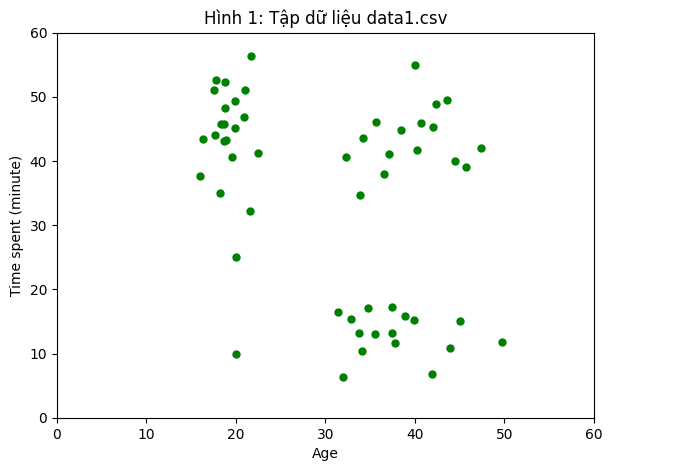

In [5]:
plot_data_p2(df1)

Quan sát các điểm dữ liệu trong `data1.csv` bạn nghĩ đâu là các điểm dữ liệu ngoại lai?  
Ý tưởng của thuật toán phát hiện điểm dữ liệu ngoại lai như sau:
1. Với mỗi điểm dữ liệu $i$ ta tính tổng khoảng cách giữa điểm dữ liệu đó với $K$ điểm dữ liệu gần
nhất, gọi giá trị này là $d_i$.
2. $M$ điểm dữ liệu ngoại lai cần loại bỏ là $M$ điểm dữ liệu có giá trị $d_i$ lớn nhất.

Bạn hãy hoàn thiện hàm `predict` trong class `OutliersDetector` theo ý tưởng trên, sau đó sử dụng
để phát hiện các điểm dữ liệu ngoại lai trong `data1.csv`.

Ta nhận thấy rằng thuật toán phát hiện dữ liệu ngoại lai này không có sử dụng nhãn dữ liệu trong
quá trình huấn luyện nên được gọi là thuật toán học không giám sát (unsupervised learning).

In [6]:
class OutliersDetector:
    def __init__(self, K: int) -> None:
        """
        Input: K - number of nearest neighbors
        """
        self.K = K

    def __distance(self, a : np.ndarray, b : np.ndarray) -> np.ndarray:
        return np.linalg.norm(a-b)

    def fit(self, X : np.ndarray) -> None:
        """
        Input: X (ndarray) - datapoints
        """
        self.X_train = X

    def predict(self, M : int) -> list[int]:
        """
        Input: M - Number of outliers
        Output: result(array) - Indexes of outliers from X_train 
        """
        
        # *** START CODE HERE *** 
        result = []
        raise NotImplementedError
        return result
        # *** END CODE HERE ***

In [8]:
# Run this cell to test your result

K = 5; M = 5
od = OutliersDetector(K)
od.fit(X1)
idxes = od.predict(M)

assert set(idxes) == {27, 3, 23, 0, 21}
print("Passed!")
plot_data3(X1, idxes)

In [ ]:
# Run this cell to test your result

K = 7; M = 10
od = OutliersDetector(K)
od.fit(X1)
idxes = od.predict(M)

assert set(idxes) == {27, 3, 23, 0, 21, 39, 14, 49, 5, 48}
print("Passed!")
plot_data3(X1, idxes)